In [75]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


PROJECT_DIR = Path.cwd().parents[2]

DATA_DIR = PROJECT_DIR / "data"

EXTERNAL_DIR = DATA_DIR / "external"

V2_DATA_DIR = DATA_DIR / "v2_5year_seoul"
PROCESSED_DIR = V2_DATA_DIR / "processed"


TRADE_BASE_PATH = (
    PROCESSED_DIR
    / "df_fe_base.parquet"
)

LOAN_RATE_PATH = (
    EXTERNAL_DIR
    / "mortgage_rent_loan_rate_monthly.csv"
)

BASE_RATE_PATH = (
    EXTERNAL_DIR
    / "한국은행_기준금리.csv"
)

RATE_FEATURE_PATH = (
    PROCESSED_DIR
    / "df_fe_rate.parquet"
)


print("PROJECT_DIR:", PROJECT_DIR)
print("EXTERNAL_DIR:", EXTERNAL_DIR)
print("PROCESSED_DIR:", PROCESSED_DIR)

print("\n대출금리:", LOAN_RATE_PATH.exists())
print("기준금리:", BASE_RATE_PATH.exists())
print("매매 기본:", TRADE_BASE_PATH.exists())

PROJECT_DIR: c:\Users\uk\Apartment price
EXTERNAL_DIR: c:\Users\uk\Apartment price\data\external
PROCESSED_DIR: c:\Users\uk\Apartment price\data\v2_5year_seoul\processed

대출금리: True
기준금리: True
매매 기본: True


In [76]:
loan_rate_raw = pd.read_csv(
    LOAN_RATE_PATH,
)

base_rate_raw = pd.read_csv(
    BASE_RATE_PATH,
)

trade_base = pd.read_parquet(
    TRADE_BASE_PATH,
)

print("대출금리:", loan_rate_raw.shape)
display(loan_rate_raw.head())

print("\n기준금리:", base_rate_raw.shape)
display(base_rate_raw.head())

print("\n매매 기본 데이터:", trade_base.shape)

대출금리: (2, 72)


,통계표,계정항목,단위,변환,2020/12,2021/01,2021/02,2021/03,2021/04,2021/05,...,2025/10,2025/11,2025/12,2026/01,2026/02,2026/03,2026/04,2026/05,2026/06,2026/07 p)
0,1.3.3.2.1. 예금은행 대출금리(신규취급액 기준),주택담보대출,연리%,원자료,2.59,2.63,2.66,2.73,2.73,2.69,...,3.98,4.17,4.23,4.29,4.32,4.34,4.31,4.32,4.36,4.48
1,1.3.3.2.1. 예금은행 대출금리(신규취급액 기준),전세자금대출,연리%,원자료,2.58,2.59,2.57,2.57,2.57,2.52,...,3.78,3.90,3.99,4.06,4.06,4.07,4.01,3.97,4.07,4.19



기준금리: (1, 72)


,통계표,계정항목,단위,변환,2020/12,2021/01,2021/02,2021/03,2021/04,2021/05,...,2025/10,2025/11,2025/12,2026/01,2026/02,2026/03,2026/04,2026/05,2026/06,2026/07
0,1.3.1. 한국은행 기준금리 및 여수신금리,한국은행 기준금리,연%,원자료,0.5,0.5,0.5,0.5,0.5,0.5,...,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.75



매매 기본 데이터: (234302, 69)


In [77]:
# ============================================================
# 한국은행 기준금리 세로형 변환
# ============================================================

base_rate = (
    base_rate_raw
    .melt(
        var_name="연월",
        value_name="기준금리",
    )
)

base_rate = base_rate[
    base_rate["연월"]
    .astype(str)
    .str.match(r"\d{4}[./-]\d{2}")
].copy()

base_rate["거래월일자"] = pd.to_datetime(
    base_rate["연월"]
    .astype(str)
    .str.replace(".", "-", regex=False)
    .str.replace("/", "-", regex=False)
    + "-01",
    errors="coerce",
)

base_rate["기준금리"] = pd.to_numeric(
    base_rate["기준금리"],
    errors="coerce",
)

base_rate = (
    base_rate[
        ["거래월일자", "기준금리"]
    ]
    .dropna(subset=["거래월일자"])
    .sort_values("거래월일자")
    .reset_index(drop=True)
)

display(base_rate.head())
display(base_rate.tail())

print("shape:", base_rate.shape)
print("기간:", base_rate["거래월일자"].min(), "~", base_rate["거래월일자"].max())

,거래월일자,기준금리
0,2020-12-01,0.5
1,2021-01-01,0.5
2,2021-02-01,0.5
3,2021-03-01,0.5
4,2021-04-01,0.5


,거래월일자,기준금리
63,2026-03-01,2.50
64,2026-04-01,2.50
65,2026-05-01,2.50
66,2026-06-01,2.50
67,2026-07-01,2.75


shape: (68, 2)
기간: 2020-12-01 00:00:00 ~ 2026-07-01 00:00:00


In [78]:
# ============================================================
# 금리 분석기간 정리
# ============================================================

RATE_START = pd.Timestamp("2020-12-01")
RATE_END = pd.Timestamp("2026-06-01")

base_rate = (
    base_rate[
        base_rate["거래월일자"].between(
            RATE_START,
            RATE_END,
        )
    ]
    .reset_index(drop=True)
)

print("shape:", base_rate.shape)
print(
    "기간:",
    base_rate["거래월일자"].min(),
    "~",
    base_rate["거래월일자"].max(),
)

shape: (67, 2)
기간: 2020-12-01 00:00:00 ~ 2026-06-01 00:00:00


In [79]:
print("대출금리 shape:", loan_rate_raw.shape)

print("\n컬럼:")
print(loan_rate_raw.columns.tolist())

display(loan_rate_raw.head())
display(loan_rate_raw.tail())

대출금리 shape: (2, 72)

컬럼:
['통계표', '계정항목', '단위', '변환', '2020/12', '2021/01', '2021/02', '2021/03', '2021/04', '2021/05', '2021/06', '2021/07', '2021/08', '2021/09', '2021/10', '2021/11', '2021/12', '2022/01', '2022/02', '2022/03', '2022/04', '2022/05', '2022/06', '2022/07', '2022/08', '2022/09', '2022/10', '2022/11', '2022/12', '2023/01', '2023/02', '2023/03', '2023/04', '2023/05', '2023/06', '2023/07', '2023/08', '2023/09', '2023/10', '2023/11', '2023/12', '2024/01', '2024/02', '2024/03', '2024/04', '2024/05', '2024/06', '2024/07', '2024/08', '2024/09', '2024/10', '2024/11', '2024/12', '2025/01', '2025/02', '2025/03', '2025/04', '2025/05', '2025/06', '2025/07', '2025/08', '2025/09', '2025/10', '2025/11', '2025/12', '2026/01', '2026/02', '2026/03', '2026/04', '2026/05', '2026/06', '2026/07 p)']


,통계표,계정항목,단위,변환,2020/12,2021/01,2021/02,2021/03,2021/04,2021/05,...,2025/10,2025/11,2025/12,2026/01,2026/02,2026/03,2026/04,2026/05,2026/06,2026/07 p)
0,1.3.3.2.1. 예금은행 대출금리(신규취급액 기준),주택담보대출,연리%,원자료,2.59,2.63,2.66,2.73,2.73,2.69,...,3.98,4.17,4.23,4.29,4.32,4.34,4.31,4.32,4.36,4.48
1,1.3.3.2.1. 예금은행 대출금리(신규취급액 기준),전세자금대출,연리%,원자료,2.58,2.59,2.57,2.57,2.57,2.52,...,3.78,3.90,3.99,4.06,4.06,4.07,4.01,3.97,4.07,4.19


,통계표,계정항목,단위,변환,2020/12,2021/01,2021/02,2021/03,2021/04,2021/05,...,2025/10,2025/11,2025/12,2026/01,2026/02,2026/03,2026/04,2026/05,2026/06,2026/07 p)
0,1.3.3.2.1. 예금은행 대출금리(신규취급액 기준),주택담보대출,연리%,원자료,2.59,2.63,2.66,2.73,2.73,2.69,...,3.98,4.17,4.23,4.29,4.32,4.34,4.31,4.32,4.36,4.48
1,1.3.3.2.1. 예금은행 대출금리(신규취급액 기준),전세자금대출,연리%,원자료,2.58,2.59,2.57,2.57,2.57,2.52,...,3.78,3.90,3.99,4.06,4.06,4.07,4.01,3.97,4.07,4.19


In [80]:
# ============================================================
# 주담대·전세대출 금리 세로형 변환
# ============================================================

month_cols = [
    col
    for col in loan_rate_raw.columns
    if str(col)[:4].isdigit()
]

loan_rate = (
    loan_rate_raw[
        ["계정항목"] + month_cols
    ]
    .melt(
        id_vars="계정항목",
        var_name="연월",
        value_name="금리",
    )
)

loan_rate["연월"] = (
    loan_rate["연월"]
    .str.extract(r"(\d{4}/\d{2})")[0]
)

loan_rate["거래월일자"] = pd.to_datetime(
    loan_rate["연월"] + "/01",
    format="%Y/%m/%d",
)

loan_rate["금리"] = pd.to_numeric(
    loan_rate["금리"],
    errors="coerce",
)

loan_rate = (
    loan_rate
    .pivot(
        index="거래월일자",
        columns="계정항목",
        values="금리",
    )
    .reset_index()
)

display(loan_rate.head())
display(loan_rate.tail())

print("shape:", loan_rate.shape)
print("컬럼:", loan_rate.columns.tolist())

계정항목,거래월일자,전세자금대출,주택담보대출
0,2020-12-01,2.58,2.59
1,2021-01-01,2.59,2.63
2,2021-02-01,2.57,2.66
3,2021-03-01,2.57,2.73
4,2021-04-01,2.57,2.73


계정항목,거래월일자,전세자금대출,주택담보대출
63,2026-03-01,4.07,4.34
64,2026-04-01,4.01,4.31
65,2026-05-01,3.97,4.32
66,2026-06-01,4.07,4.36
67,2026-07-01,4.19,4.48


shape: (68, 3)
컬럼: ['거래월일자', '        전세자금대출', '      주택담보대출']


In [81]:
print(
    "기간:",
    loan_rate["거래월일자"].min(),
    "~",
    loan_rate["거래월일자"].max(),
)

print("\n결측치:")
print(loan_rate.isna().sum())

print("\n계정항목:")
print(loan_rate.columns.tolist())

기간: 2020-12-01 00:00:00 ~ 2026-07-01 00:00:00

결측치:
계정항목
거래월일자             0
        전세자금대출    0
      주택담보대출      0
dtype: int64

계정항목:
['거래월일자', '        전세자금대출', '      주택담보대출']


In [82]:
# ============================================================
# 대출금리 컬럼명 정리
# ============================================================

loan_rate.columns = [
    str(col).strip()
    for col in loan_rate.columns
]

loan_rate = loan_rate.rename(
    columns={
        "주택담보대출": "주담대금리",
        "전세자금대출": "전세대출금리",
    }
)

print(loan_rate.columns.tolist())
display(loan_rate.head())

['거래월일자', '전세대출금리', '주담대금리']


,거래월일자,전세대출금리,주담대금리
0,2020-12-01,2.58,2.59
1,2021-01-01,2.59,2.63
2,2021-02-01,2.57,2.66
3,2021-03-01,2.57,2.73
4,2021-04-01,2.57,2.73


In [83]:
# ============================================================
# 기준금리 + 대출금리 통합
# ============================================================

rate_monthly = (
    base_rate
    .merge(
        loan_rate,
        on="거래월일자",
        how="inner",
        validate="one_to_one",
    )
    .sort_values("거래월일자")
    .reset_index(drop=True)
)

print("shape:", rate_monthly.shape)

print(
    "기간:",
    rate_monthly["거래월일자"].min(),
    "~",
    rate_monthly["거래월일자"].max(),
)

print("\n결측치:")
print(rate_monthly.isna().sum())

display(rate_monthly.head())
display(rate_monthly.tail())

shape: (67, 4)
기간: 2020-12-01 00:00:00 ~ 2026-06-01 00:00:00

결측치:
거래월일자     0
기준금리      0
전세대출금리    0
주담대금리     0
dtype: int64


,거래월일자,기준금리,전세대출금리,주담대금리
0,2020-12-01,0.5,2.58,2.59
1,2021-01-01,0.5,2.59,2.63
2,2021-02-01,0.5,2.57,2.66
3,2021-03-01,0.5,2.57,2.73
4,2021-04-01,0.5,2.57,2.73


,거래월일자,기준금리,전세대출금리,주담대금리
62,2026-02-01,2.5,4.06,4.32
63,2026-03-01,2.5,4.07,4.34
64,2026-04-01,2.5,4.01,4.31
65,2026-05-01,2.5,3.97,4.32
66,2026-06-01,2.5,4.07,4.36


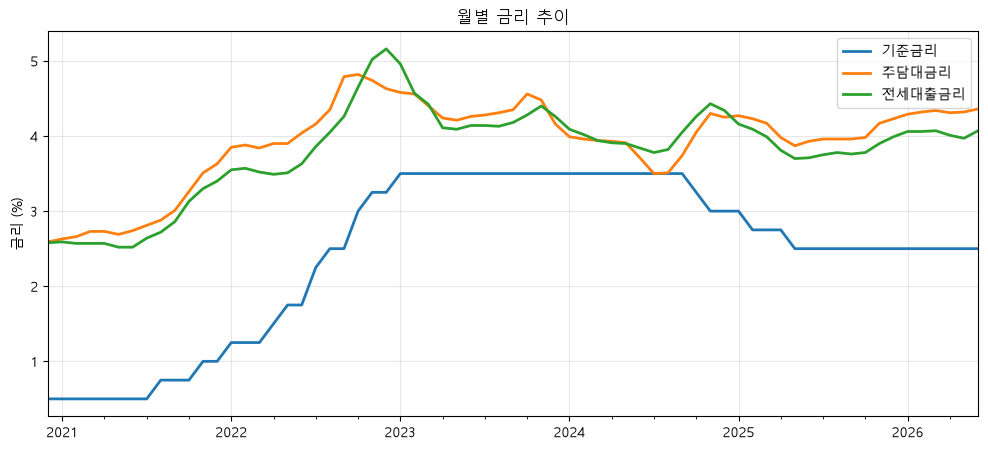

In [84]:
# ============================================================
# 금리 시계열 EDA
# ============================================================

rate_monthly.set_index("거래월일자")[
    [
        "기준금리",
        "주담대금리",
        "전세대출금리",
    ]
].plot(
    figsize=(12, 5),
    linewidth=2,
)

plt.title("월별 금리 추이")
plt.xlabel("")
plt.ylabel("금리 (%)")
plt.grid(alpha=0.3)
plt.show()

In [85]:
# ============================================================
# 매매 데이터 기간 확인
# ============================================================

trade_base["거래월일자"] = pd.to_datetime(
    trade_base["거래월일자"]
)

print(
    "매매 기간:",
    trade_base["거래월일자"].min(),
    "~",
    trade_base["거래월일자"].max(),
)

print(
    "매매 월 수:",
    trade_base["거래월일자"]
    .dt.to_period("M")
    .nunique(),
)

매매 기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00
매매 월 수: 60


In [86]:
print("shape:", rate_monthly.shape)
print("\ndtype:")
print(rate_monthly.dtypes)

display(rate_monthly.head())

shape: (67, 4)

dtype:
거래월일자     datetime64[ns]
기준금리             float64
전세대출금리           float64
주담대금리            float64
dtype: object


,거래월일자,기준금리,전세대출금리,주담대금리
0,2020-12-01,0.5,2.58,2.59
1,2021-01-01,0.5,2.59,2.63
2,2021-02-01,0.5,2.57,2.66
3,2021-03-01,0.5,2.57,2.73
4,2021-04-01,0.5,2.57,2.73


In [87]:
# ============================================================
# 금리 Lag / 변화량 Feature
# ============================================================

rate_features = rate_monthly.copy()

rate_cols = [
    "기준금리",
    "주담대금리",
    "전세대출금리",
]

for col in rate_cols:
    rate_features[f"{col}_전월"] = (
        rate_features[col].shift(1)
    )

    rate_features[f"{col}_3개월변화"] = (
        rate_features[col].shift(1)
        - rate_features[col].shift(4)
    )

    rate_features[f"{col}_6개월변화"] = (
        rate_features[col].shift(1)
        - rate_features[col].shift(7)
    )

display(rate_features.tail())

,거래월일자,기준금리,전세대출금리,주담대금리,기준금리_전월,기준금리_3개월변화,기준금리_6개월변화,주담대금리_전월,주담대금리_3개월변화,주담대금리_6개월변화,전세대출금리_전월,전세대출금리_3개월변화,전세대출금리_6개월변화
62,2026-02-01,2.5,4.06,4.32,2.5,0.0,0.0,4.29,0.31,0.33,4.06,0.28,0.31
63,2026-03-01,2.5,4.07,4.34,2.5,0.0,0.0,4.32,0.15,0.36,4.06,0.16,0.28
64,2026-04-01,2.5,4.01,4.31,2.5,0.0,0.0,4.34,0.11,0.38,4.07,0.08,0.31
65,2026-05-01,2.5,3.97,4.32,2.5,0.0,0.0,4.31,0.02,0.33,4.01,-0.05,0.23
66,2026-06-01,2.5,4.07,4.36,2.5,0.0,0.0,4.32,0.00,0.15,3.97,-0.09,0.07


In [88]:
# ============================================================
# 모델 대상 기간 추출
# ============================================================

MODEL_START = trade_base["거래월일자"].min()
MODEL_END = trade_base["거래월일자"].max()

rate_model = (
    rate_features[
        rate_features["거래월일자"]
        .between(MODEL_START, MODEL_END)
    ]
    .reset_index(drop=True)
)

feature_cols = [
    f"{col}_{feature}"
    for col in rate_cols
    for feature in [
        "전월",
        "3개월변화",
        "6개월변화",
    ]
]

print("shape:", rate_model.shape)
print(
    "기간:",
    rate_model["거래월일자"].min(),
    "~",
    rate_model["거래월일자"].max(),
)

print("\n금리 피처 결측:")
print(
    rate_model[feature_cols]
    .isna()
    .sum()
)

shape: (60, 13)
기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00

금리 피처 결측:
기준금리_전월         0
기준금리_3개월변화      0
기준금리_6개월변화      0
주담대금리_전월        0
주담대금리_3개월변화     0
주담대금리_6개월변화     0
전세대출금리_전월       0
전세대출금리_3개월변화    0
전세대출금리_6개월변화    0
dtype: int64


1️⃣ 세션(메모리) 유지 방식
예: store = {}, ChatMessageHistory, InMemorySaver
- 특징
    - 서버 메모리에만 대화 상태를 저장
    - 서버 재시작/재배포 시 모두 사라짐
    - 구현이 가장 단순하고 빠름
- 사용 시기
    - 실습 / 데모 / PoC
    - 단일 서버, 짧은 대화
    - “지금 이 세션에서만 기억하면 되는” 경우
- 장단점
    - ✅ 속도 빠름, 구현 쉬움
    - ❌ 서버 내려가면 기억 소멸
    - ❌ 멀티 서버(스케일아웃) 불가능

2️⃣ SQLite 체크포인터
예: SqliteSaver, checkpoint.db
- 특징
    - 로컬 파일(DB)에 대화 상태 저장
    - 서버 재시작해도 대화 복원 가능
    - 설정/운영 부담이 거의 없음
- 사용 시기
    - 1대 서버 운영
    - “재접속 시 대화 이어가기”가 중요한 서비스
    - 내부 도구, 사내용 챗봇, 파일 기반 서비스
- 장단점
    - ✅ 재시작해도 대화 유지
    - ✅ 설정 간단 (파일 하나)
    - ❌ 동시접속/대량 트래픽에 취약
    - ❌ 운영·분석·확장성 한계

3️⃣ RDB (MySQL / PostgreSQL 등)
실무에서 가장 많이 쓰는 방식

- 특징
    - 대화 내역을 정규화된 테이블로 저장
    - 여러 서버가 공유 DB 사용 가능
    - 사용자/세션/대화/이력 분석까지 가능
- 사용 시기
    - 실서비스(운영 환경)
    - 로그인 사용자 기반 챗봇
    - 고객지원, 상담, 금융, 헬스케어, 교육 서비스
- 장단점
    - ✅ 서버 여러 대에서도 동일한 대화 유지
    - ✅ 로그/분석/감사/리포트 가능
    - ✅ 권한·보안·백업 체계화 가능
    - ❌ 설계/운영 비용 존재

- 요약하자면  
메모리 세션    : 빠르고 간단  
SQLite 같은 파일형 DB : 재접속 기억 + 운영 부담 최소  
RDB    같은 관계형 데이터베이스 : 확장성, 안정성, 분석, 운영  

- 서비스 구상 단계에서  
사용자별 히스토리 관리  
문제 발생 시 감사 로그  
대화 품질/모델 성능 분석  
요약/임베딩/재검색(RAG) 연계  
개인화 서비스(추천, 성향 파악)  
이걸 하려면 RDB 또는 그 이상(이벤트 로그, 데이터 웨어하우스) 가 필요

In [89]:
# ============================================================
# 매매 거래에 금리 Feature 결합
# ============================================================

rate_for_merge = rate_model[
    ["거래월일자"] + feature_cols
].copy()

before_rows = len(trade_base)

trade_rate = trade_base[
    ["transaction_id", "거래월일자"]
].merge(
    rate_for_merge,
    on="거래월일자",
    how="left",
    validate="many_to_one",
)

print(
    "행 수:",
    before_rows,
    "→",
    len(trade_rate),
)

print("\n금리 피처 결측:")
print(
    trade_rate[feature_cols]
    .isna()
    .sum()
)

행 수: 234302 → 234302

금리 피처 결측:
기준금리_전월         0
기준금리_3개월변화      0
기준금리_6개월변화      0
주담대금리_전월        0
주담대금리_3개월변화     0
주담대금리_6개월변화     0
전세대출금리_전월       0
전세대출금리_3개월변화    0
전세대출금리_6개월변화    0
dtype: int64


In [90]:
# ============================================================
# 최종 금리 feature-only 데이터
# ============================================================

df_fe_rate = trade_rate[
    ["transaction_id"] + feature_cols
].copy()

print("shape:", df_fe_rate.shape)

print(
    "transaction_id 중복:",
    df_fe_rate["transaction_id"]
    .duplicated()
    .sum(),
)

display(df_fe_rate.head())

shape: (234302, 10)
transaction_id 중복: 0


,transaction_id,기준금리_전월,기준금리_3개월변화,기준금리_6개월변화,주담대금리_전월,주담대금리_3개월변화,주담대금리_6개월변화,전세대출금리_전월,전세대출금리_3개월변화,전세대출금리_6개월변화
0,0,0.5,0.0,0.0,2.74,0.01,0.15,2.52,-0.05,-0.06
1,1,0.5,0.0,0.0,2.74,0.01,0.15,2.52,-0.05,-0.06
2,2,0.5,0.0,0.0,2.74,0.01,0.15,2.52,-0.05,-0.06
3,3,0.5,0.0,0.0,2.74,0.01,0.15,2.52,-0.05,-0.06
4,4,0.5,0.0,0.0,2.74,0.01,0.15,2.52,-0.05,-0.06


In [91]:
# ============================================================
# 월별 금리 Feature 확인
# ============================================================

check_rate = trade_rate[
    ["거래월일자"] + feature_cols
].drop_duplicates(
    subset=["거래월일자"]
)

display(check_rate.head(12))

,거래월일자,기준금리_전월,기준금리_3개월변화,기준금리_6개월변화,주담대금리_전월,주담대금리_3개월변화,주담대금리_6개월변화,전세대출금리_전월,전세대출금리_3개월변화,전세대출금리_6개월변화
0,2021-07-01,0.50,0.00,0.00,2.74,0.01,0.15,2.52,-0.05,-0.06
46,2021-08-01,0.50,0.00,0.00,2.81,0.08,0.18,2.64,0.07,0.05
83,2021-09-01,0.75,0.25,0.25,2.88,0.19,0.22,2.72,0.20,0.15
116,2021-10-01,0.75,0.25,0.25,3.01,0.27,0.28,2.86,0.34,0.29
159,2021-11-01,0.75,0.25,0.25,3.26,0.45,0.53,3.13,0.49,0.56
183,2021-12-01,1.00,0.25,0.50,3.51,0.63,0.82,3.30,0.58,0.78
200,2022-01-01,1.00,0.25,0.50,3.63,0.62,0.89,3.40,0.54,0.88
216,2022-02-01,1.25,0.50,0.75,3.85,0.59,1.04,3.55,0.42,0.91
231,2022-03-01,1.25,0.25,0.50,3.88,0.37,1.00,3.57,0.27,0.85
251,2022-04-01,1.25,0.25,0.50,3.84,0.21,0.83,3.52,0.12,0.66


In [92]:
print(
    "거래월 수:",
    trade_rate["거래월일자"].nunique(),
)

print("\n금리 피처별 고유값 수:")
print(
    trade_rate[feature_cols]
    .nunique()
)

거래월 수: 60

금리 피처별 고유값 수:
기준금리_전월         12
기준금리_3개월변화       6
기준금리_6개월변화      10
주담대금리_전월        46
주담대금리_3개월변화     56
주담대금리_6개월변화     58
전세대출금리_전월       49
전세대출금리_3개월변화    53
전세대출금리_6개월변화    57
dtype: int64


In [93]:
# ============================================================
# 금리 Feature 최종 저장
# ============================================================

rate_feature_cols = [
    "기준금리_전월",
    "기준금리_3개월변화",
    "기준금리_6개월변화",
    "주담대금리_전월",
    "주담대금리_3개월변화",
    "주담대금리_6개월변화",
    "전세대출금리_전월",
    "전세대출금리_3개월변화",
    "전세대출금리_6개월변화",
]

df_fe_rate = trade_rate[
    ["transaction_id"] + rate_feature_cols
].copy()

df_fe_rate.to_parquet(
    PROCESSED_DIR / "df_fe_rate.parquet",
    index=False,
)

print("shape:", df_fe_rate.shape)
print(
    "transaction_id 중복:",
    df_fe_rate["transaction_id"].duplicated().sum(),
)
print(
    "결측치:",
    df_fe_rate[rate_feature_cols].isna().sum().sum(),
)
print(
    "저장 완료:",
    PROCESSED_DIR / "df_fe_rate.parquet",
)

shape: (234302, 10)
transaction_id 중복: 0
결측치: 0
저장 완료: c:\Users\uk\Apartment price\data\v2_5year_seoul\processed\df_fe_rate.parquet
